In [3]:
# conda env 'misr'

import MisrToolkit as mtk
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

In [4]:
def nearest_sample(lat, lon, path, resolution):
    region = mtk.MtkRegion(lat,lon, 1, 1, "km")
    lats, lons = region.snap_to_grid(path, resolution).create_latlon()
    lats = lats.ravel()
    lons = lons.ravel()
    lat_diff = lats - lat
    lon_diff = lons - lon
    D = (lat_diff**2 + lon_diff**2)**0.5
    return lats[np.argmin(D)], lons[np.argmin(D)]

In [5]:
# region_title = 'CAMP2Ex_RF17_Pris'
# out_file = '../intermediate_data/CTH_flat_top.nc'

database = '../../data/MISR'
path = 117
orbit = 105254
cameras = ['DF', 'CF', 'BF', 'AF', 'AN', 'AA', 'BA', 'CA', 'DA']
close_lat = 18.7363627835159
close_lon = 120.347313848168
lat, lon = nearest_sample(close_lat, close_lon, path, 17600)

In [6]:
tc_cloud_general = '{}/MISR_AM1_TC_CLOUD_P{:d}_O{:d}_F01_0001.hdf'
# region = mtk.MtkRegion(path, 74, 76) # RF17
region = mtk.MtkRegion(lat, lon, 8.8*3, 8.8*3, "km")
lat1100, lon1100 = region.snap_to_grid(path, 1100).create_latlon()
lat17600, lon17600 = region.snap_to_grid(path, 17600).create_latlon()

In [7]:
grp_general = '{}/MISR_AM1_GRP_ELLIPSOID_GM_P{:d}_O{:d}_{}_F03_0024.hdf'
nadir_file = grp_general.format(database, path, orbit, 'AN')
lat275, lon275 = region.snap_to_grid(path, 275).create_latlon()
brf = mtk.MtkFile(nadir_file).grid('RedBand').field('Red Brf').read(region).data()

In [8]:
tc_cloud_file = tc_cloud_general.format(database, path, orbit)
tc_cloud_grid = mtk.MtkFile(tc_cloud_file).grid('Stereo_1.1_km')
CTH = tc_cloud_grid.field('CloudTopHeight').read(region).data().astype(np.float32)
CTH[CTH == -9999] = np.nan
CM = tc_cloud_grid.field('StereoDerivedCloudMask').read(region).data().astype(np.float32)
CM[CM == 0] = np.nan
SQUI = tc_cloud_grid.field('StereoQualityIndicator').read(region).data().astype(np.float32)
SQUI[SQUI == -128] = np.nan

In [9]:
# cloud_data = xr.Dataset(
#     data_vars = {
#         'cth': (['y1100', 'x1100'], CTH),
#         'cm': (['y1100', 'x1100'], CM),
#         'squi': (['y1100', 'x1100'], SQUI),
#         'lat1100': (['y1100', 'x1100'], lat1100),
#         'lon1100': (['y1100', 'x1100'], lon1100),
#         'center_lat': region.center[0],
#         'center_lon': region.center[1]
#     },
#     attrs = {
#         'orbit': orbit,
#         'path': path,
#         'blocks': region.block_range(path),
#     }
# )
# cloud_data['cth'] = (['y1100', 'x1100'], 1400 * np.ones(CTH.shape)) ## Force into a slab cloud
# cloud_data['cth'].attrs['units'] = 'm'
# cloud_data['cth'].attrs['long_name'] = 'Cloud Top Height'
# cloud_data['cm'].attrs['long_name'] = 'Cloud Mask'
# cloud_data['squi'].attrs['long_name'] = 'Stereo Quality Indicator'
# # cloud_data.to_netcdf(out_file)

[299.5 309.5 319.5 329.5 339.5 349.5 359.5 369.5 379.5 389.5 399.5 409.5
 419.5 429.5 439.5 449.5 459.5 469.5 479.5 489.5 499.5 509.5 519.5 529.5
 539.5 549.5 559.5 569.5 579.5 589.5 599.5 609.5 619.5 629.5 639.5 649.5
 659.5 669.5 679.5 689.5 699.5 709.5 719.5 729.5 739.5 749.5 759.5 769.5
 779.5 789.5 799.5 809.5 819.5 829.5 839.5 849.5 859.5 869.5 879.5 889.5
 899.5]


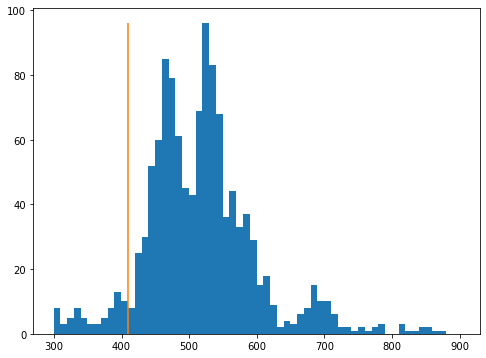

In [17]:
f, ax = plt.subplots(1, 1, figsize=(8,6))
bins = np.concatenate((np.arange(-311, 0, 10)+0.5, np.arange(0, 1400, 100)+0.5))
bins = np.arange(299, 901, 10) + 0.5
h = ax.hist(np.ravel(CTH), bins=bins)
ax.vlines(409.5, 0, np.max(h[0]), colors='tab:orange')
print(h[1])

Target: (18.736362783515954, 120.34731384816892)


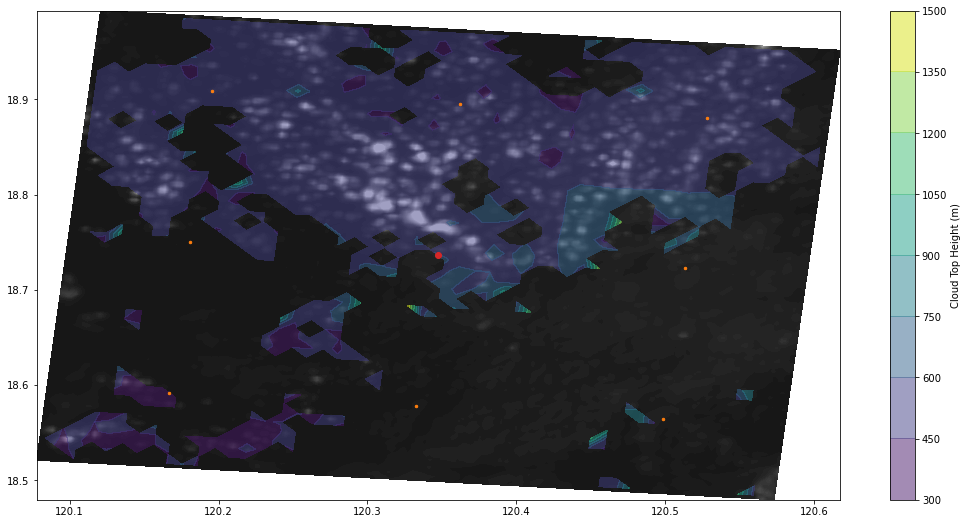

In [16]:
tar_lat, tar_lon = nearest_sample(18.8, 120.4, path, 17600)
f, ax = plt.subplots(1, 1, figsize=(18,9))
ax.contourf(lon275, lat275, brf, cmap='gray', levels=100, vmin=0, vmax=0.3)
levels = np.concatenate((np.array([-400, 0]), np.arange(300, 801, 25)))
nanCTH = CTH.copy()
nanCTH[CTH < 400] = np.nan
c = ax.contourf(lon1100, lat1100, nanCTH, alpha=0.5, vmin=None, vmax=None, levels=None)
ax.scatter(np.ravel(lon17600), np.ravel(lat17600), c='tab:orange', s=6)
ax.scatter(tar_lon, tar_lat, c='tab:red')
plt.colorbar(c, label='Cloud Top Height (m)')
# ax.set_xlim([118, 123])
# ax.set_ylim([17.4, 21.5])
# ax.set_xlim([119.5, 120.9])
# ax.set_ylim([18.0, 19.7])
print('Target: ({}, {})'.format(tar_lat, tar_lon))

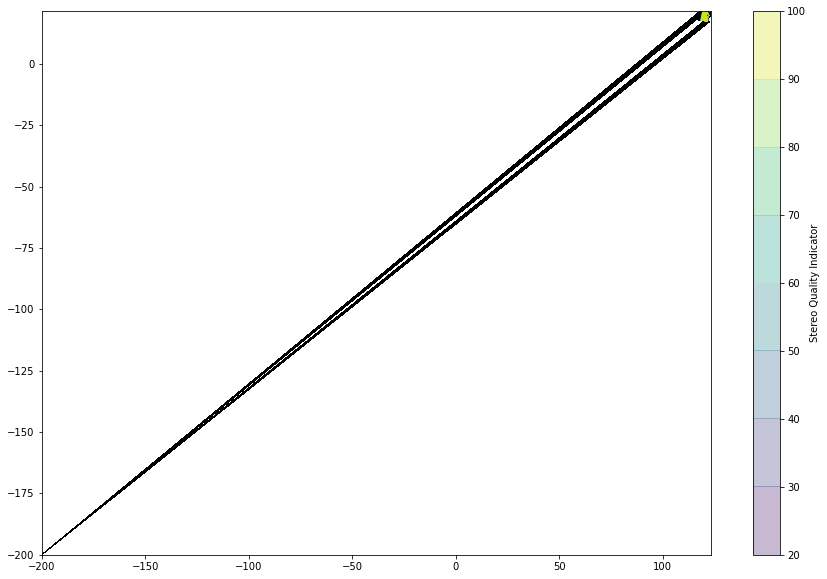

In [48]:
f, ax = plt.subplots(1, 1, figsize=(15,10))
ax.contourf(lon275, lat275, brf, cmap='gray', levels=100)
c = ax.contourf(lon1100, lat1100, SQUI, alpha=0.3)
plt.colorbar(c, label='Stereo Quality Indicator')

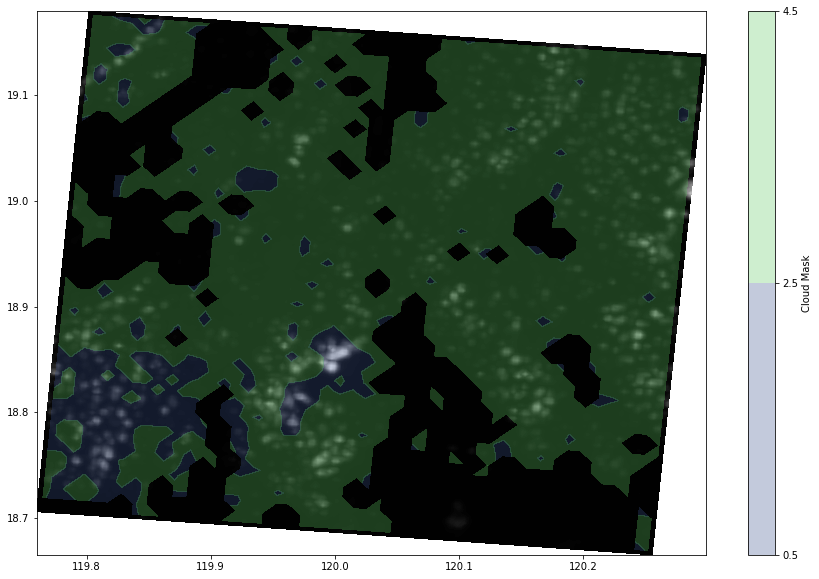

In [19]:
f, ax = plt.subplots(1, 1, figsize=(15,10))
ax.contourf(lon275, lat275, brf, cmap='gray', levels=100)
# c = ax.contourf(lon1100, lat1100, CM, alpha=0.3, levels=np.array([0.5, 1.5, 2.5, 3.5, 4.5]))
c = ax.contourf(lon1100, lat1100, CM, alpha=0.3, levels=np.array([0.5, 2.5, 4.5]))
plt.colorbar(c, label='Cloud Mask')

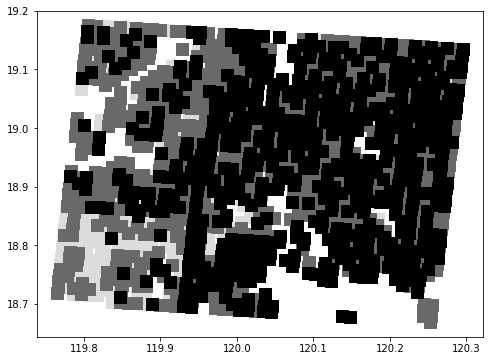

In [20]:
s = 130
f, ax = plt.subplots(1, 1, figsize=(8,6))
cond_nd = CM == 0
cond_hcc = CM == 1
cond_lcc = CM == 2
cond_lcs = CM == 3
cond_hcs = CM == 4
ax.scatter(lon1100[cond_nd], lat1100[cond_nd], c='r', marker='s', s=s, label='No Data')
ax.scatter(lon1100[cond_hcc], lat1100[cond_hcc], c='w', marker='s', s=s, label='High Confidence Cloud')
ax.scatter(lon1100[cond_lcc], lat1100[cond_lcc], c='gainsboro', marker='s', s=s, label='Low Confidence Cloud')
ax.scatter(lon1100[cond_lcs], lat1100[cond_lcs], c='dimgray', marker='s', s=s, label='Low Confidence Clear')
ax.scatter(lon1100[cond_hcs], lat1100[cond_hcs], c='k', marker='s', s=s, label='High Confidence Clear')
# ax.legend(loc='right')
